# 01 – Build the Batch Master Table

**Run this notebook only when the pulled data changes** (after `python pull_data.py`).
It reads the pulled sensor data and the real lab samples, builds the tables and saves them to `data/`:

| File | 1 row = | Used by |
|---|---|---|
| `data/batch_master.csv` | 1 batch | `02_analysis.ipynb`, Excel |
| `data/lab_linked.csv` | 1 real lab sample (with its digester and batch) | `02_analysis.ipynb` |

Sections 3–6 are **checks**: look at them before trusting the analysis. No PI access in this notebook.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

from pull_data import load_data
from lab import load_lab_samples
from build_master import build_master, save_outputs

## 1. Load the pulled sensor data and the real lab samples

In [2]:
df = load_data(config.data_name())
print("Sensor data:", df.shape, df.index.min(), "->", df.index.max())

lab = load_lab_samples(refresh=True)   # refresh=True re-reads the log book Excel files
print("Lab samples:", len(lab), lab.index.min(), "->", lab.index.max())

Sensor data: (67105, 127) 2026-03-01 00:00:00 -> 2026-10-20 00:00:00
Reading 1.LINE NO.2_Log Sheet_2025 in JAN 2026.xlsx
Reading 2.LINE NO.2_Log Sheet_2026 in FEB 2026.xlsx
Reading 3.LINE NO.2_Log Sheet_2026 in march 2026.xlsx
Reading 4.LINE NO.2_Log Sheet_2026 in APR 2026.xlsx
Reading 5.LINE NO.2_Log Sheet_2026 in MAY 2026.xlsx
Reading 6.LINE NO.2_Log Sheet_ in JUN 2026 Rev.01.xlsx
Reading 7.LINE NO.2_Log Sheet_ in JUL 2026.xlsx
Reading 8.LINE NO.2_Log Sheet_ in Aug 2026.xlsx
Reading 09. LINE NO.2_Log Sheet_ in Sep 2026.xlsx
Reading 10. LINE NO.2_Log Sheet_ in Oct 2026.xlsx.48024.1793330845.tmp
Lab samples: 2756 2026-01-01 08:00:00 -> 2026-10-30 08:00:00


## 2. Build and save the tables

In [3]:
master, phases, lab_linked, phases_summary, phases_summary_lab = build_master(df, lab)
save_outputs(master, lab_linked, phases_summary, phases_summary_lab)
print(f"\nBatch Master Table: {master.shape[0]} batches x {master.shape[1]} columns")
print(f"Phase Summary Table: {phases_summary.shape[0]} phase runs x {phases_summary.shape[1]} columns")
print(f"Phase Summary (with lab): {phases_summary_lab.shape[0]} phase runs x {phases_summary_lab.shape[1]} columns")
master.head()

d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\lab.py:55: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table.insert(0, lab_column, values)


Saved 3105 batches    -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\batch_master.csv
Saved 2705 lab rows -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\lab_linked.csv
Saved 20316 phase runs -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\phase_summary.csv
Saved 20316 phase runs (with lab) -> d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\Digester_Analysis\data\phase_summary_with_lab.csv

Batch Master Table: 3105 batches x 88 columns
Phase Summary Table: 20316 phase runs x 121 columns
Phase Summary (with lab): 20316 phase runs x 129 columns


,digester,batch_id,batch_number,batch_start,batch_end,batch_hours,chip_filling_start,chip_filling_end,chip_filling_minutes,prehydrolysis_start,prehydrolysis_end,prehydrolysis_minutes,hot_liquor_filling_start,hot_liquor_filling_end,hot_liquor_filling_minutes,heat_and_cook_start,heat_and_cook_end,heat_and_cook_minutes,displacement_start,displacement_end,displacement_minutes,discharge_start,discharge_end,discharge_minutes,wait_start,wait_end,wait_minutes,unknown_phase_count,h_factor,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait,chip_weight_max_chip_filling,ventilation_temp_max_chip_filling,pfactor_actual_last_prehydrolysis,pfactor_setpoint_last_prehydrolysis,...,circulation_temp_max_hot_liquor_filling,white_liquor_dosing_flow_mean_hot_liquor_filling,alkali_accumulator1_conc_mean_hot_liquor_filling,alkali_accumulator2_conc_mean_hot_liquor_filling,hbl_accumulator_cond_mean_hot_liquor_filling,circulation_temp_max_heat_and_cook,circulation_temp_mean_heat_and_cook,bottom_circulation_temp_mean_heat_and_cook,digester_pressure_mean_heat_and_cook,steam_to_heater_flow_mean_heat_and_cook,LP_pressure_mean_heat_and_cook,steam_heater_temp_max_heat_and_cook,screen_diff_pressure_mean_heat_and_cook,circulation_pump_current_mean_heat_and_cook,displacement_liquor_temp_mean_displacement,black_liquor_conductivity_mean_displacement,pfactor_final,pfactor_overshoot,ptemp_overshoot,minutes_above_165,minutes_above_168,steam_users_other,liquor_to_wood_ratio,white_liquor_m3,white_liquor_per_ton_chip,pfactor_gap,pfactor_rate,press1_kappa,press1_kappa_samples,press1_kappa_first_time,press1_viscosity,press1_viscosity_samples,press1_viscosity_first_time,press1_brightness,press1_brightness_samples,press1_brightness_first_time,kappa_grade,viscosity_grade,overall_grade,quality_flag
0,1,1,7016.0,2026-03-01 00:00:00,2026-03-01 07:10:00,7.166667,2026-03-01 00:00:00,2026-03-01 00:20:00,20.0,2026-03-01 00:25:00,2026-03-01 01:25:00,60.0,2026-03-01 01:30:00,2026-03-01 02:35:00,65.0,2026-03-01 02:40:00,2026-03-01 03:25:00,45.0,2026-03-01 03:30:00,2026-03-01 04:05:00,35.0,2026-03-01 04:10:00,2026-03-01 07:10:00,180.0,NaT,NaT,NaN,0,526.275589,0.082436,0.289029,260.427244,175.919264,89.929080,0.477222,NaN,85.107399,93.0,334.377594,350.0,...,166.963898,10.664062,36.924861,14.622367,-6.200428,158.399231,151.743790,156.061894,6.079365,7.084002,6.883811,163.656250,-1.875,71.741861,144.650650,48.972656,410.929077,60.929077,NaN,35.0,25.0,0.384615,1.499146,11.552734,0.135743,-15.622406,5.572960,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaN,ok
1,1,2,7019.0,2026-03-01 07:15:00,2026-03-01 16:45:00,9.500000,2026-03-01 07:15:00,2026-03-01 11:50:00,275.0,2026-03-01 11:55:00,2026-03-01 13:05:00,70.0,2026-03-01 13:10:00,2026-03-01 14:15:00,65.0,2026-03-01 14:20:00,2026-03-01 15:00:00,40.0,2026-03-01 15:05:00,2026-03-01 15:40:00,35.0,2026-03-01 15:45:00,2026-03-01 15:55:00,10.0,2026-03-01 16:00:00,2026-03-01 16:45:00,45.0,0,482.183864,0.661563,0.116731,194.396811,179.673653,108.113400,0.035488,0.152604,84.425041,93.0,324.090942,350.0,...,163.445770,9.576172,36.878162,14.385681,-6.307547,158.475632,152.956894,150.284391,6.247032,3.056830,7.060222,161.664062,-1.875,71.361142,141.130708,48.972656,402.432281,52.432281,NaN,35.0,25.0,0.000000,1.524668,10.374186,0.122880,-25.909058,4.629871,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaT,NaN,NaN,NaN,ok
2,1,3,7022.0,2026-03-01 16:50:00,2026-03-01 22:05:00,5.250000,2026-03-01 16:50:00,2026-03-01 17:25:00,35.0,2026-03-01 17:30:00,2026-03-01 18:40:00,70.0,2026-03-01 18:45:00,2026-03-01 19:50:00,65.0,2026-03-01 19:55:00,2026-03-01 20:25:00,30.0,2026-03-01 20:30:00,2026-03-01 21:05:00,35.0,2026-03-01 21:10:00,2026-03-01 22:05:00,55.0,NaT,NaT,NaN,0,604.611252,0.123457,0.234817,323.335839,172.468075,108.807337,0.195170,NaN,86.996429,93.0,345.715363,350.0,...,168.580978,10.337891,36.795648,14.491954,-6.231803,159.019531,156.102038,158.987207,6.085868,4.476894,6.889614,162.585938,-1.875,68.134064,141.050112,48.9

## 3. Check – quality flags

`ok` = normal batch. Other flags (nothing is removed, `02_analysis` uses only `ok` by default):
- `missing_phase` – no HEAT&COOK or no DISCHARGE (sequence broken, or cut at the start/end of the data)
- `unknown_phase` – phase text that is not a real phase (e.g. "8", "0" = PI system states)
- `long_batch` – longer than `config.LONG_BATCH_HOURS` (probably includes a stop)
- `no_h_factor` – H-factor missing or 0

In [4]:
display(pd.crosstab(master["quality_flag"], master["digester"], margins=True))

digester,1,2,3,4,All
quality_flag,,,,,
long_batch,19,20,16,70,125
missing_phase,0,0,1,0,1
missing_phase;long_batch;no_h_factor,1,2,0,0,3
missing_phase;no_h_factor,6,4,4,6,20
missing_phase;unknown_phase;long_batch,2,0,0,0,2
ok,841,854,855,359,2909
unknown_phase,9,7,14,5,35
unknown_phase;long_batch,1,2,3,4,10
All,879,889,893,444,3105


## 4. Check – in which phase does the cooking (H-factor) happen?

Median H-factor added in each phase per batch (only `ok` batches).
`h_factor` = sum of the phases in `config.H_FACTOR_PHASES`.
If a phase outside `H_FACTOR_PHASES` has a large H, the H-factor window may be wrong.
**D4**: its temperature tag (`TI423`) behaves differently (high H during PREHYDRAU) – D4 is provisional.

In [5]:
ok = master[master["quality_flag"] == "ok"]
h_cols = [f"h_{s}" for s in config.PHASE_NAMES.values() if f"h_{s}" in master]
display(ok.groupby("digester")[h_cols + ["h_factor"]].median().round(1))

share = ok[h_cols].div(ok[h_cols].sum(axis=1), axis=0) * 100
print("Share of the total H in each phase (% , median):")
display(share.groupby(ok["digester"]).median().round(1))

,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait,h_factor
digester,,,,,,,,
1,0.1,0.3,291.1,162.5,89.2,0.1,0.1,545.7
2,0.1,0.2,111.6,167.1,93.2,0.1,0.1,367.8
3,0.1,0.2,56.6,167.7,108.6,0.1,0.1,339.4
4,0.1,602.2,161.5,169.9,72.1,0.1,0.1,414.2


Share of the total H in each phase (% , median):


,h_chip_filling,h_prehydrolysis,h_hot_liquor_filling,h_heat_and_cook,h_displacement,h_discharge,h_wait
digester,,,,,,,
1,0.0,0.0,53.3,30.0,16.5,0.0,0.0
2,0.0,0.1,30.2,45.1,23.0,0.0,0.0
3,0.0,0.0,17.4,49.6,26.6,0.0,0.0
4,0.0,56.4,16.6,16.5,7.3,0.0,0.0


## 5. Check – temperature profile of example batches

Red = circulation temperature (used for H-factor), dark red dashed = bottom circulation, blue = pressure.
Coloured bands = phases. Change `EXAMPLE_FROM` to look at other days.

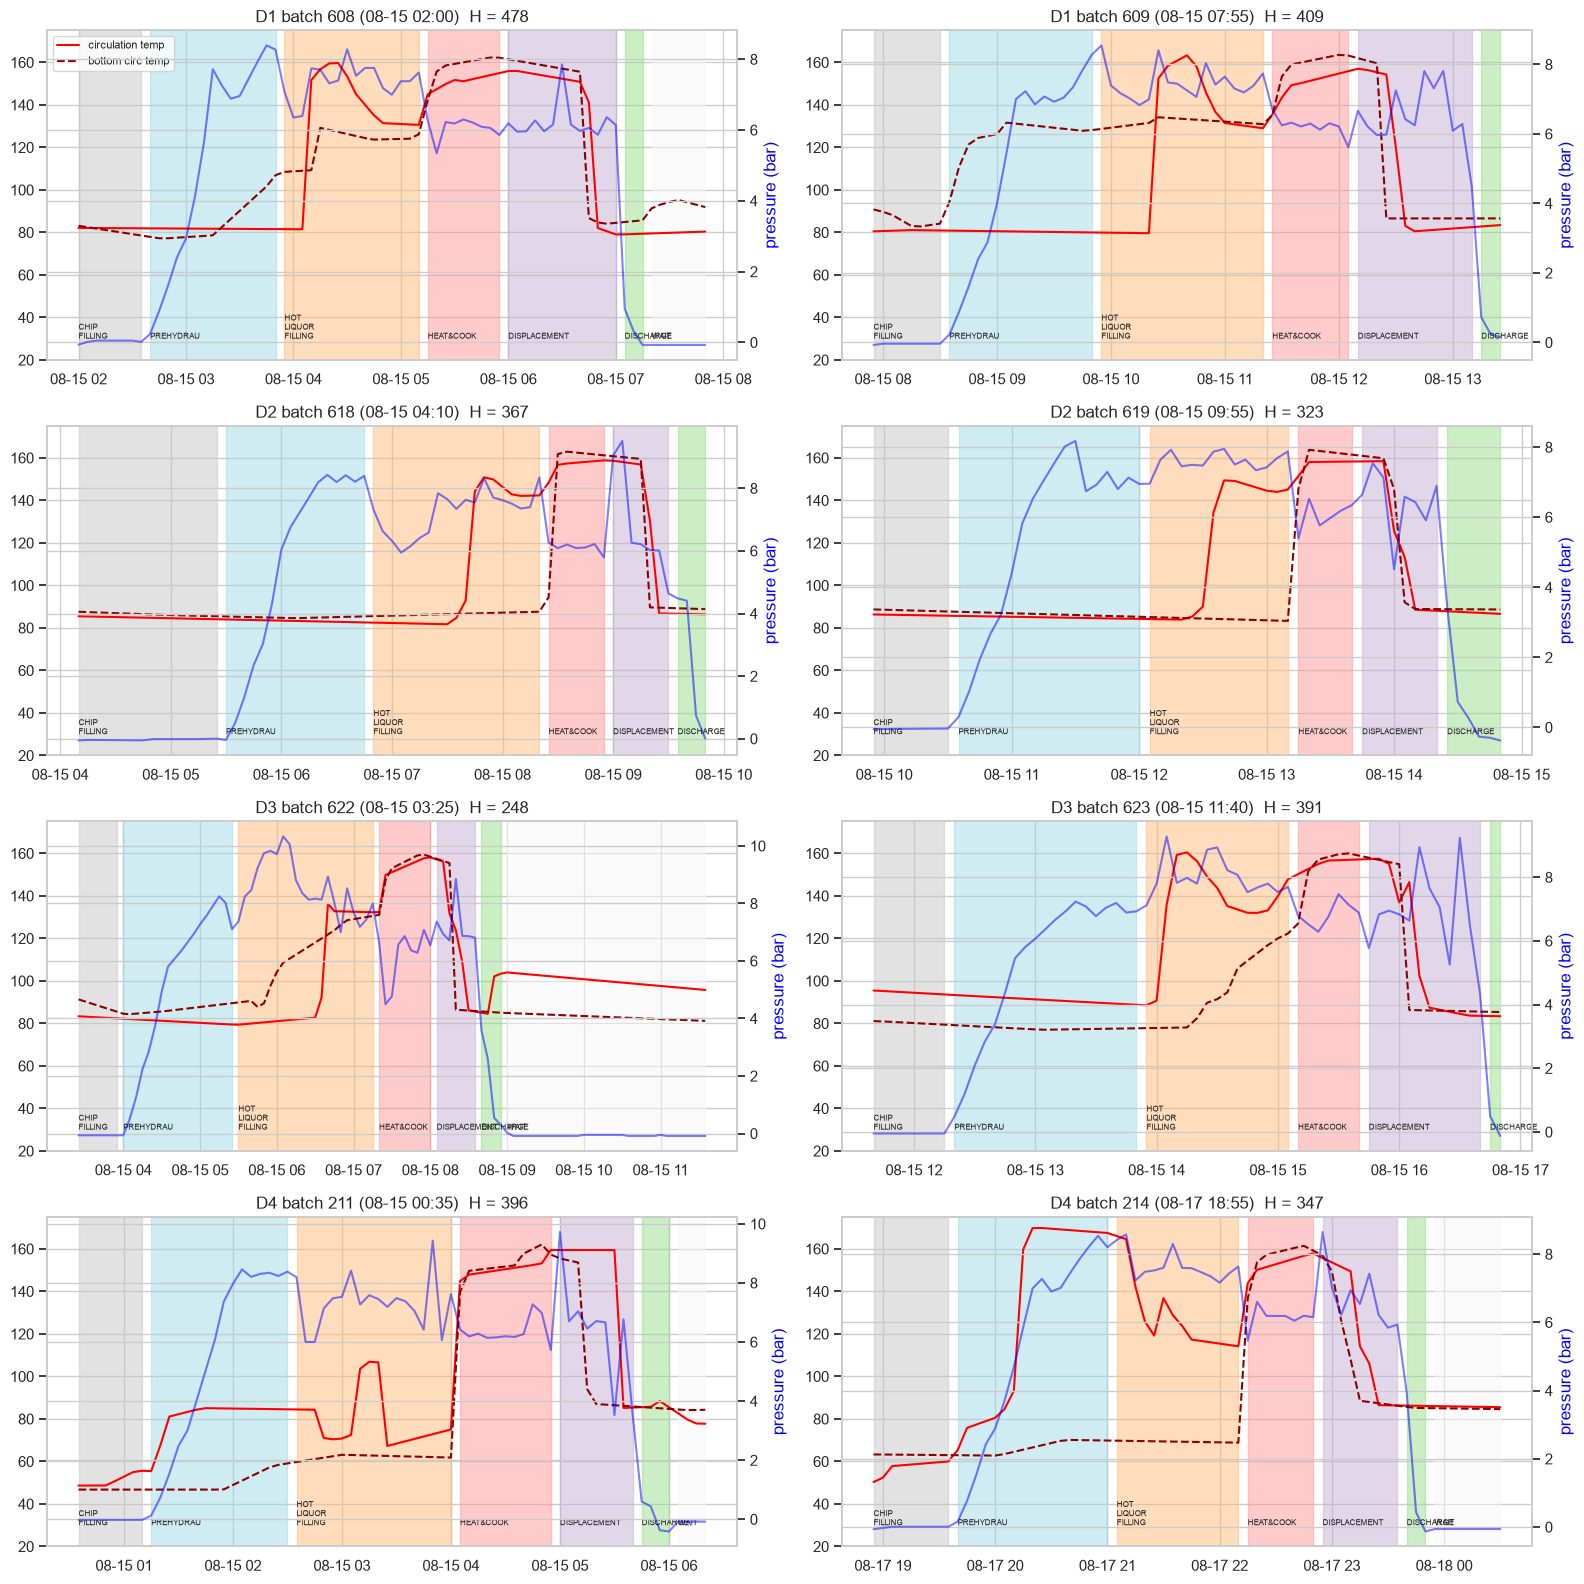

In [6]:
EXAMPLE_FROM = "2026-08-15"
PHASE_COLORS = {"CHIP FILLING": "#c7c7c7", "PREHYDRAU": "#9edae5", "HOT LIQUOR FILLING": "#ffbb78",
                "HEAT&COOK": "#ff9896", "DISPLACEMENT": "#c5b0d5", "DISCHARGE": "#98df8a", "WAIT": "#f7f7f7"}

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
for row, dig in enumerate([1, 2, 3, 4]):
    examples = ok[(ok["digester"] == dig) & (ok["batch_start"] >= EXAMPLE_FROM)].head(2)
    for col, (_, b) in enumerate(examples.iterrows()):
        ax = axes[row, col]
        part = df.loc[b["batch_start"]:b["batch_end"]]
        ax.plot(part.index, part[f"D{dig}_circulation_temp"], color="red", label="circulation temp")
        ax.plot(part.index, part[f"D{dig}_bottom_circulation_temp"], color="darkred", linestyle="--", label="bottom circ temp")
        ax2 = ax.twinx()
        ax2.plot(part.index, part[f"D{dig}_digester_pressure"], color="blue", alpha=0.5)
        ax2.set_ylabel("pressure (bar)", color="blue")
        for p in phases[(phases["digester"] == dig) & (phases["batch_id"] == b["batch_id"])].itertuples():
            ax.axvspan(p.start, p.end, color=PHASE_COLORS.get(p.phase, "yellow"), alpha=0.5)
            ax.text(p.start, 30, p.phase.replace(" ", "\n"), fontsize=6)
        ax.set_ylim(20, 175)
        ax.set_title(f"D{dig} batch {b['batch_id']} ({b['batch_start']:%m-%d %H:%M})  H = {b['h_factor']:.0f}")
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 6. Check – lab samples linked to a batch

Lab time → digester at Press 1 (`Dk_press1_status == k`) → that digester's latest batch discharged before the sample.
Samples with no single digester at Press 1 are not linked.

In [7]:
print("Real lab samples with a digester, and how many were linked to a batch:")
display(lab_linked.groupby(["parameter", "digester"])["batch_id"].agg(samples="size", linked="count").unstack("digester"))

print("Batches that have a Kappa value:", master["press1_kappa"].notna().sum(), "of", len(master))

Real lab samples with a digester, and how many were linked to a batch:


samples                linked               
digester                1    2    3    4      1    2    3    4
parameter                                                     
press1_brightness     305  356  414  249    304  355  414  246
press1_kappa          169  189  211  123    168  188  211  121
press1_viscosity      165  190  211  123    164  189  211  121

Batches that have a Kappa value: 686 of 3105


**Next:** open `02_analysis.ipynb` (it only reads the saved CSV files).